<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Multilayer_Example_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

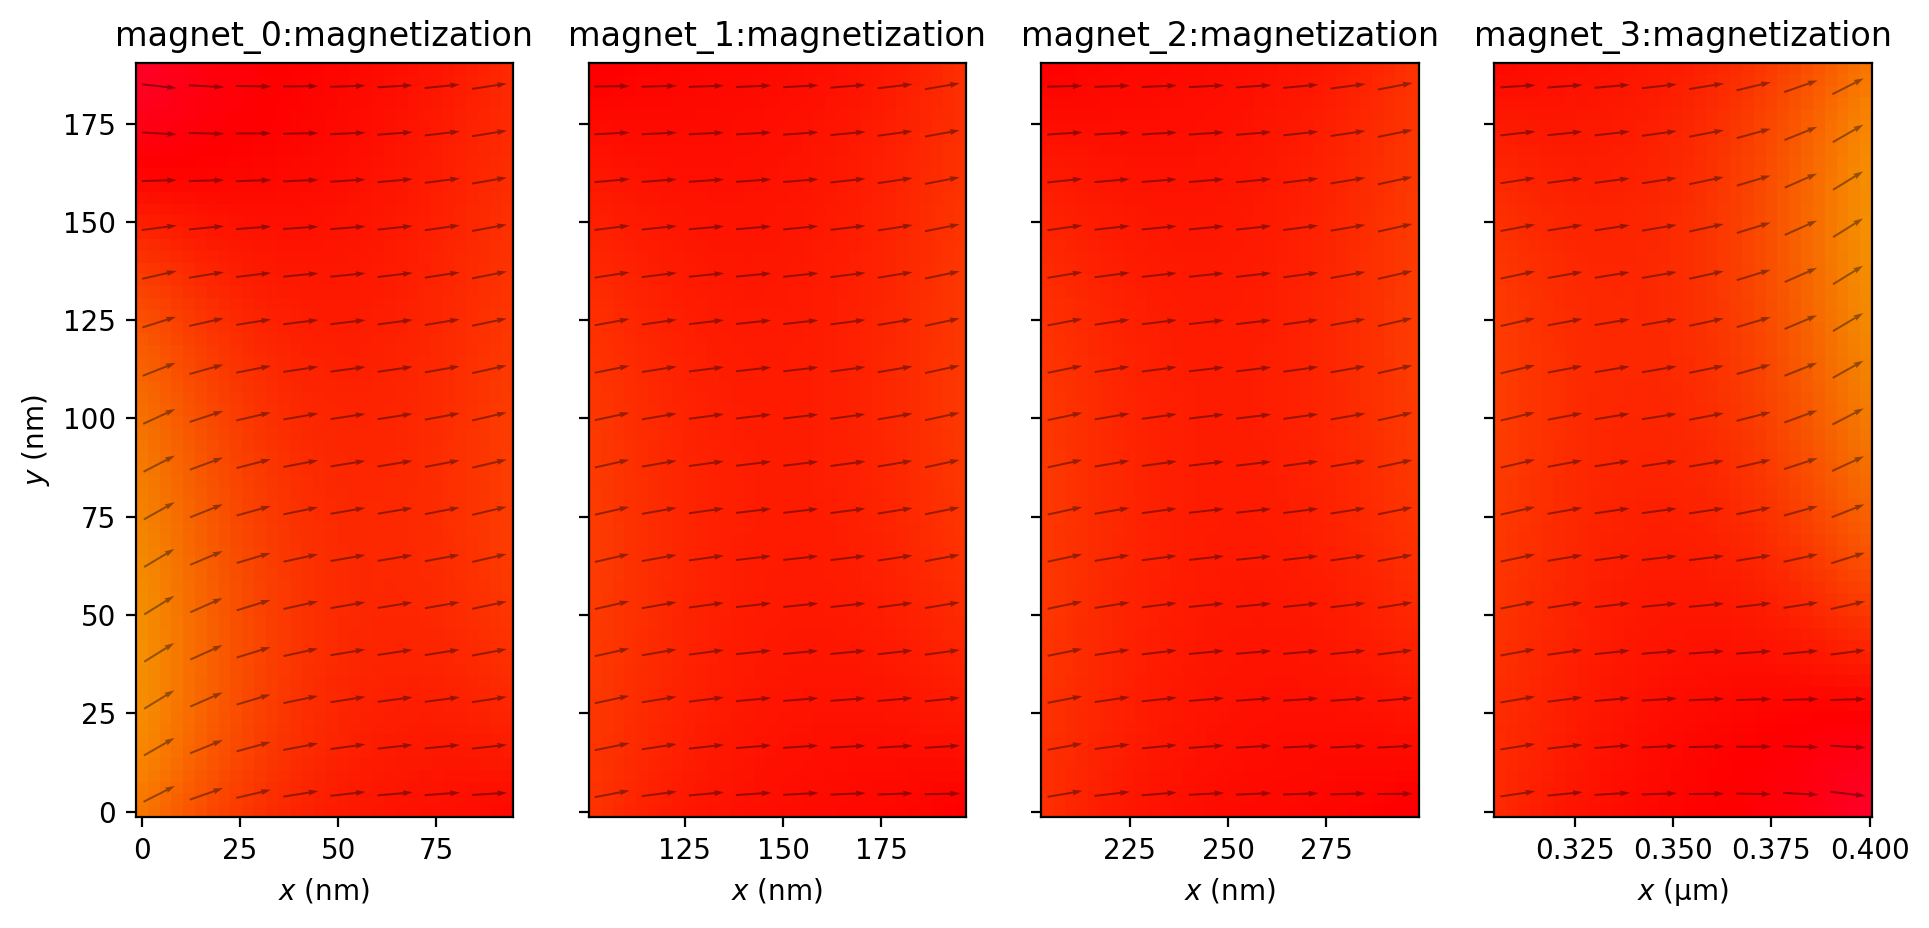

In [3]:
import matplotlib.pyplot as plt
import numpy as np

from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util import plot_field

plt.rcParams['figure.dpi'] = 200

world = World(cellsize=(3e-9, 3e-9, 3e-9))

gridsize = (32, 64, 1)
offset = 34
n_magnets = 4

magnets = []
for i in range(n_magnets):
    grid = Grid(gridsize, origin=(i * offset, 0, 0))
    magnet = Ferromagnet(world, grid,  name=f"magnet_{i}")
    magnet.aex = 13e-12
    magnet.alpha = 0.5
    magnet.msat = 800e3
    magnet.magnetization = (1, 0.1, 0)
    magnets.append(magnet)

world.timesolver.run(1e-10)

fig, axs = plt.subplots(nrows=1, ncols=n_magnets, figsize=(2.8*n_magnets, 5.3), sharey="all")
for i, (magnet, ax) in enumerate(zip(magnets, axs)):
    plot_field(magnet.magnetization, ax=ax, arrow_size=4,
               ylabel=None if i==0 else "")
plt.show()